# Potato growth-stage detection: verified-data fine-tuning experiment

Run cells in order. The experiment uses the existing verified YOLO dataset and adds pseudo-labels only when a reviewer has marked the image `approved` or `approved_empty`, supplied a reviewer and review date, and saved the corrected YOLO label under `preannotations/approved_labels/`. Unreviewed predictions are counted and excluded.

The existing test split is copied nowhere, never used for training or model selection, and evaluated read-only for both checkpoints. The existing capture IDs are disjoint across train, validation, and test. Source plot groups overlap across these splits, so validation is capture-separated but **not plot-independent**, and the test comparison has the same existing plot-group limitation.

## 1. Environment setup

In [3]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import csv, hashlib, json, math, re, shutil, time, gc

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
VERIFIED_DATASET = PROJECT_ROOT / "potato_yolo_dataset"
ORIGINAL_DATA_YAML = VERIFIED_DATASET / "data.yaml"
ANNOTATIONS_CSV = PROJECT_ROOT / "annotations.csv"
PREANNOTATION_ROOT = PROJECT_ROOT / "preannotations"
APPROVAL_CSV = PREANNOTATION_ROOT / "manual_approval.csv"
APPROVED_LABELS = PREANNOTATION_ROOT / "approved_labels"
TILE_ROOT = PROJECT_ROOT / "tiles_640_final"
RGB_ROOT = PROJECT_ROOT / "dataset" / "RGB images"
BASE_CHECKPOINT = PROJECT_ROOT / "runs" / "potato_yolov8n" / "weights" / "best.pt"
CLASS_NAMES = {0: "Vegetative", 1: "Tuber Bulking", 2: "Maturity"}
CLASS_COLORS = {0: (60, 180, 75), 1: (0, 165, 255), 2: (70, 70, 220)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CAPTURE_PATTERN = re.compile(r"IMG\d{14}", re.IGNORECASE)
EXPERIMENT_ROOT = PROJECT_ROOT / "runs" / "potato_yolov8n_finetune"
EXPERIMENT_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
EXPERIMENT_DIR = EXPERIMENT_ROOT / EXPERIMENT_ID
PREPARED_DATASET = EXPERIMENT_DIR / "dataset"
PREPARED_YAML = PREPARED_DATASET / "data.yaml"
EPOCHS, IMAGE_SIZE, INITIAL_BATCH = 100, 640, 2
DEVICE = 0 if torch.cuda.is_available() else "cpu"

assert VERIFIED_DATASET.is_dir() and ORIGINAL_DATA_YAML.is_file(), "Verified dataset or its YAML is missing."
assert BASE_CHECKPOINT.is_file(), f"Fine-tuning checkpoint is missing: {BASE_CHECKPOINT}"
assert not EXPERIMENT_DIR.exists(), f"Refusing to overwrite existing experiment: {EXPERIMENT_DIR}"
print("Project:", PROJECT_ROOT)
print("Experiment:", EXPERIMENT_DIR)
print("Ultralytics:", __import__("ultralytics").__version__, "| PyTorch:", torch.__version__)
print("Original checkpoint:", BASE_CHECKPOINT, "| bytes:", BASE_CHECKPOINT.stat().st_size)

Project: C:\Users\simra\potato_harvest
Experiment: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701
Ultralytics: 8.4.194 | PyTorch: 2.11.0+cu128
Original checkpoint: C:\Users\simra\potato_harvest\runs\potato_yolov8n\weights\best.pt | bytes: 6510378


## 2. GPU verification

In [4]:
GPU_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else "CPU"
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3) if GPU_AVAILABLE else 0.0
BATCH_SIZE = INITIAL_BATCH if GPU_AVAILABLE else 1
print({"cuda_available": GPU_AVAILABLE, "device": GPU_NAME, "gpu_memory_gb": round(GPU_MEMORY_GB, 2), "initial_batch": BATCH_SIZE})
if GPU_AVAILABLE:
    assert "3050" in GPU_NAME or GPU_MEMORY_GB <= 6.0, "Review this GPU configuration before starting the requested 4 GB training run."

{'cuda_available': True, 'device': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'gpu_memory_gb': 4.0, 'initial_batch': 2}


## 3. Dataset inspection

In [5]:
def capture_id(value):
    m = CAPTURE_PATTERN.search(str(value))
    return m.group(0).upper() if m else None

def images_in(folder):
    folder = Path(folder)
    return sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS) if folder.exists() else []

def split_images(split):
    return images_in(VERIFIED_DATASET / "images" / split)

SPLITS = ("train", "val", "test")
SPLIT_IMAGES = {s: split_images(s) for s in SPLITS}
assert all(SPLIT_IMAGES.values()), f"Empty existing split(s): {[s for s in SPLITS if not SPLIT_IMAGES[s]]}"
CAPTURE_TO_SOURCE_GROUP = {}
for source_image in images_in(RGB_ROOT):
    cid = capture_id(source_image.stem)
    if cid:
        group = source_image.parent.name
        if cid in CAPTURE_TO_SOURCE_GROUP and CAPTURE_TO_SOURCE_GROUP[cid] != group:
            raise ValueError(f"Capture {cid} maps to multiple source folders.")
        CAPTURE_TO_SOURCE_GROUP[cid] = group

def source_group(image_path):
    cid = capture_id(image_path)
    return CAPTURE_TO_SOURCE_GROUP.get(cid, f"UNMAPPED:{cid or Path(image_path).name}")

SPLIT_CAPTURE_IDS = {s: {capture_id(p) for p in SPLIT_IMAGES[s]} for s in SPLITS}
SPLIT_CAPTURE_IDS = {s: {x for x in vals if x} for s, vals in SPLIT_CAPTURE_IDS.items()}
SPLIT_SOURCE_GROUPS = {s: {source_group(p) for p in SPLIT_IMAGES[s]} for s in SPLITS}
print("Images per existing split:", {s: len(SPLIT_IMAGES[s]) for s in SPLITS})
print("Original capture IDs per split:", {s: sorted(SPLIT_CAPTURE_IDS[s]) for s in SPLITS})
print("Mapped source groups per split:", {s: sorted(SPLIT_SOURCE_GROUPS[s]) for s in SPLITS})

Images per existing split: {'train': 199, 'val': 41, 'test': 59}
Original capture IDs per split: {'train': ['IMG20231225113918', 'IMG20231225114040', 'IMG20231227114230', 'IMG20231227115125', 'IMG20231228105347', 'IMG20231228111007'], 'val': ['IMG20231227114428'], 'test': ['IMG20231224110533', 'IMG20231224110751']}
Mapped source groups per split: {'train': ['T1_T1', 'T1_T2', 'T1_T3'], 'val': ['T1_T3'], 'test': ['T1_T2', 'T1_T3']}


## 4. Annotation inspection

In [6]:
def parse_yolo(label_path):
    rows = []
    for n, line in enumerate(Path(label_path).read_text(encoding="utf-8").splitlines(), 1):
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 5:
            raise ValueError(f"{label_path}:{n}: expected 5 fields")
        cls_f, *coords = map(float, fields)
        if not cls_f.is_integer() or int(cls_f) not in CLASS_NAMES:
            raise ValueError(f"{label_path}:{n}: unknown class ID")
        if not all(math.isfinite(v) and 0 <= v <= 1 for v in coords):
            raise ValueError(f"{label_path}:{n}: invalid normalized coordinates")
        cx, cy, w, h = coords
        if w <= 0 or h <= 0 or cx-w/2 < -1e-6 or cy-h/2 < -1e-6 or cx+w/2 > 1+1e-6 or cy+h/2 > 1+1e-6:
            raise ValueError(f"{label_path}:{n}: box outside image")
        rows.append((int(cls_f), cx, cy, w, h))
    return rows

VERIFIED_COUNTS = {s: Counter() for s in SPLITS}
VERIFIED_LABELS = {}
for split in SPLITS:
    for image_path in SPLIT_IMAGES[split]:
        label_path = VERIFIED_DATASET / "labels" / split / (image_path.stem + ".txt")
        if not label_path.is_file():
            raise FileNotFoundError(f"Missing verified label: {label_path}")
        if cv2.imread(str(image_path)) is None:
            raise ValueError(f"Unreadable dataset image: {image_path}")
        rows = parse_yolo(label_path)
        VERIFIED_LABELS[(split, image_path)] = rows
        VERIFIED_COUNTS[split].update(CLASS_NAMES[r[0]] for r in rows)

CSV_FRAME = pd.read_csv(ANNOTATIONS_CSV)
if not {"filename", "class_id", "class_name"}.issubset(CSV_FRAME.columns):
    raise ValueError("annotations.csv does not have the expected annotation columns.")
print("annotations.csv rows:", len(CSV_FRAME), "| CSV class counts:", CSV_FRAME["class_name"].value_counts().to_dict())
print("Verified class distribution before preparation:")
display(pd.DataFrame({s: {name: VERIFIED_COUNTS[s][name] for name in CLASS_NAMES.values()} for s in SPLITS}).fillna(0).astype(int))

progress_path = PREANNOTATION_ROOT / "progress.json"
summary_path = PREANNOTATION_ROOT / "reports" / "summary.json"
progress = json.loads(progress_path.read_text(encoding="utf-8")) if progress_path.is_file() else {}
preannotation_summary = json.loads(summary_path.read_text(encoding="utf-8")) if summary_path.is_file() else {}
review_rows = list(csv.DictReader(APPROVAL_CSV.open(encoding="utf-8-sig", newline=""))) if APPROVAL_CSV.is_file() else []
TRAINABLE_REVIEW_STATUSES = {"approved", "approved_empty", "edited"}
REVIEWED_STATUSES = TRAINABLE_REVIEW_STATUSES | {"rejected"}
approved_review_rows = [r for r in review_rows if r.get("review_status", "").strip().lower() in TRAINABLE_REVIEW_STATUSES]
unreviewed_count = sum(1 for r in review_rows if r.get("review_status", "").strip().lower() not in REVIEWED_STATUSES)
print("Pre-annotation run summary:", {k: preannotation_summary.get(k) for k in ("eligible_images", "processed_successfully", "zero_detections", "failed", "total_detection_instances")})
print("Manual review:", {"manifest_rows": len(review_rows), "approved_rows": len(approved_review_rows), "unreviewed_or_rejected": unreviewed_count, "corrected_label_files": sum(1 for p in APPROVED_LABELS.rglob("*.txt") if p.is_file()) if APPROVED_LABELS.exists() else 0})

annotations.csv rows: 404 | CSV class counts: {'Tuber Bulking': 183, 'Vegetative': 137, 'Maturity': 84}
Verified class distribution before preparation:


,train,val,test
Vegetative,95,22,20
Tuber Bulking,129,17,37
Maturity,47,9,28


Pre-annotation run summary: {'eligible_images': 3041, 'processed_successfully': 3017, 'zero_detections': 24, 'failed': 0, 'total_detection_instances': 7249}
Manual review: {'manifest_rows': 3041, 'approved_rows': 3001, 'unreviewed_or_rejected': 0, 'corrected_label_files': 3002}


In [7]:
from pathlib import Path

missing_label = (
    PREPARED_DATASET
    / "labels"
    / "train"
    / "IMG20231229110435_tile_001.txt"
)

print("Expected label:", missing_label)
print("Exists:", missing_label.exists())

# Search for the label anywhere inside the prepared dataset
matches = list(
    PREPARED_DATASET.rglob("IMG20231229110435_tile_001.txt")
)

print("\nMatching labels found:")
for p in matches:
    print(p)

# Find the corresponding image
images = list(
    (PREPARED_DATASET / "images" / "train").rglob(
        "IMG20231229110435_tile_001.*"
    )
)

print("\nMatching images found:")
for p in images:
    print(p)

Expected label: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701\dataset\labels\train\IMG20231229110435_tile_001.txt
Exists: False

Matching labels found:

Matching images found:


## 5. Dataset preparation

In [8]:

# ============================================================
# FIELDWISE: SAFE DATASET PREPARATION + MANIFEST + VALIDATION
# ============================================================

import hashlib
import json
import shutil
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

import yaml
import pandas as pd


# ------------------------------------------------------------
# 1. Fingerprint original test images and labels
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)

    return h.hexdigest()


TEST_FILES = [
    p for p in (
        VERIFIED_DATASET / "images" / "test"
    ).rglob("*")
    if p.is_file()
]

TEST_FILES += [
    p for p in (
        VERIFIED_DATASET / "labels" / "test"
    ).rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
]

TEST_HASHES_BEFORE = {
    str(p.relative_to(VERIFIED_DATASET)): sha256(p)
    for p in sorted(TEST_FILES)
}

print("Original test files fingerprinted:", len(TEST_HASHES_BEFORE))


# ------------------------------------------------------------
# 2. Identify eligible approved pseudo-labels
# ------------------------------------------------------------

PSEUDO_CANDIDATES = []
PSEUDO_EXCLUDED = []

for row in approved_review_rows:

    rel = Path(row["image_path"])
    status = row["review_status"].strip().lower()

    reviewer = row.get("reviewer", "").strip()
    reviewed_at = row.get("reviewed_at", "").strip()

    image_path = TILE_ROOT / rel
    label_path = (APPROVED_LABELS / rel).with_suffix(".txt")

    cid = capture_id(rel)
    group = CAPTURE_TO_SOURCE_GROUP.get(cid)

    if (
        not reviewer
        or not reviewed_at
        or not image_path.is_file()
        or not label_path.is_file()
    ):
        raise ValueError(
            f"Approved pseudo-label lacks reviewer/date "
            f"or corrected image/label: {rel}"
        )

    corrected_rows = parse_yolo(label_path)

    if status == "approved" and not corrected_rows:
        raise ValueError(
            f"Approved row has no corrected boxes: {rel}"
        )

    if status == "approved_empty" and corrected_rows:
        raise ValueError(
            f"Approved-empty label must have zero boxes: {rel}"
        )

    if status not in ("approved", "approved_empty", "edited"):
        raise ValueError(
            f"Unexpected review status in approved rows: {status}"
        )

    if not cid or group is None:
        PSEUDO_EXCLUDED.append(
            (str(rel), "source capture/group cannot be mapped")
        )
        continue

    if (
        cid in SPLIT_CAPTURE_IDS["val"]
        or cid in SPLIT_CAPTURE_IDS["test"]
        or group not in SPLIT_SOURCE_GROUPS["train"]
        or group in SPLIT_SOURCE_GROUPS["val"]
        or group in SPLIT_SOURCE_GROUPS["test"]
    ):
        PSEUDO_EXCLUDED.append(
            (str(rel), "would overlap validation/test capture or source group")
        )
        continue

    PSEUDO_CANDIDATES.append(
        (image_path, label_path, rel, corrected_rows, cid, group)
    )


print("Eligible pseudo-label candidates:", len(PSEUDO_CANDIDATES))
print("Excluded pseudo-label candidates:", len(PSEUDO_EXCLUDED))


# ------------------------------------------------------------
# 3. Prepare dataset only if it does not already exist
# ------------------------------------------------------------

if not PREPARED_DATASET.exists():

    print("\nPrepared dataset does not exist. Creating it...")

    for split in ("train", "val"):

        for image_path in SPLIT_IMAGES[split]:

            # Preserve relative directory structure
            rel = Path(image_path.name)

            dst_image = (
                PREPARED_DATASET / "images" / split / rel
            )

            dst_label = (
                PREPARED_DATASET / "labels" / split
                / rel.with_suffix(".txt")
            )

            dst_image.parent.mkdir(parents=True, exist_ok=True)
            dst_label.parent.mkdir(parents=True, exist_ok=True)

            source_label = (
                VERIFIED_DATASET / "labels" / split
                / (image_path.stem + ".txt")
            )

            if not source_label.is_file():
                raise FileNotFoundError(
                    f"Verified label missing: {source_label}"
                )

            shutil.copy2(image_path, dst_image)
            shutil.copy2(source_label, dst_label)

    for (
        image_path,
        label_path,
        rel,
        corrected_rows,
        cid,
        group
    ) in PSEUDO_CANDIDATES:

        dst_image = (
            PREPARED_DATASET / "images" / "train" / rel
        )

        dst_label = (
            PREPARED_DATASET / "labels" / "train"
            / rel.with_suffix(".txt")
        )

        if dst_image.exists() or dst_label.exists():
            raise FileExistsError(
                f"Pseudo-label destination collision: {rel}"
            )

        dst_image.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(image_path, dst_image)
        shutil.copy2(label_path, dst_label)

else:

    print(
        "\nPrepared dataset already exists. "
        "Reusing existing files; no copying performed."
    )


# ------------------------------------------------------------
# 4. Create dataset YAML
# ------------------------------------------------------------

prepared_yaml_data = {
    "path": str(PREPARED_DATASET.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": str(
        (VERIFIED_DATASET / "images" / "test").resolve()
    ),
    "names": CLASS_NAMES,
}

PREPARED_DATASET.mkdir(parents=True, exist_ok=True)

PREPARED_YAML.write_text(
    yaml.safe_dump(
        prepared_yaml_data,
        sort_keys=False,
        allow_unicode=True
    ),
    encoding="utf-8"
)

print("\nDataset YAML saved:", PREPARED_YAML)


# ------------------------------------------------------------
# 5. Generate manifest using nested relative paths
# ------------------------------------------------------------

manifest = []

for split in ("train", "val"):

    image_root = PREPARED_DATASET / "images" / split
    label_root = PREPARED_DATASET / "labels" / split

    if not image_root.is_dir():
        raise FileNotFoundError(
            f"Image directory missing: {image_root}"
        )

    if not label_root.is_dir():
        raise FileNotFoundError(
            f"Label directory missing: {label_root}"
        )

    for image_path in sorted(image_root.rglob("*")):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative_image = image_path.relative_to(image_root)

        # Important: retain nested subdirectories
        label_path = (
            label_root / relative_image.with_suffix(".txt")
        )

        if not label_path.is_file():
            raise FileNotFoundError(
                f"Missing label for image: {image_path}\n"
                f"Expected label: {label_path}"
            )

        rows = parse_yolo(label_path)

        source_kind = (
            "verified"
            if (
                VERIFIED_DATASET
                / "images"
                / split
                / relative_image
            ).is_file()
            else "manually_approved_pseudo"
        )

        manifest.append({
            "split": split,
            "image": str(
                image_path.relative_to(PREPARED_DATASET)
            ),
            "label": str(
                label_path.relative_to(PREPARED_DATASET)
            ),
            "source": source_kind,
            "capture_id": capture_id(image_path),
            "source_group": source_group(image_path),
            "box_count": len(rows),
            "class_counts": dict(
                Counter(
                    CLASS_NAMES[r[0]]
                    for r in rows
                )
            )
        })


# ------------------------------------------------------------
# 6. Save dataset manifest
# ------------------------------------------------------------

manifest_path = (
    PREPARED_DATASET / "dataset_manifest.json"
)

manifest_path.write_text(
    json.dumps(
        {
            "created_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),

            "verified_dataset": str(VERIFIED_DATASET),

            "pseudo_label_policy": (
                "Only approved, approved_empty, or edited rows "
                "with reviewer/date and saved labels; "
                "pending and rejected excluded."
            ),

            "unreviewed_pseudo_images_excluded": unreviewed_count,

            "human_reviewed_pseudo_included": len(
                PSEUDO_CANDIDATES
            ),

            "human_reviewed_pseudo_excluded_for_group_safety": (
                PSEUDO_EXCLUDED
            ),

            "preserved_test": str(
                (
                    VERIFIED_DATASET
                    / "images"
                    / "test"
                ).resolve()
            ),

            "items": manifest
        },
        indent=2
    ),
    encoding="utf-8"
)

print("\nManifest generated successfully!")
print("Total manifest records:", len(manifest))


# ------------------------------------------------------------
# 7. Count prepared images and class instances
# ------------------------------------------------------------

def count_prepared(split):

    counts = Counter()

    image_root = PREPARED_DATASET / "images" / split
    label_root = PREPARED_DATASET / "labels" / split

    image_files = [
        p for p in image_root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image in image_files:

        relative_image = image.relative_to(image_root)

        label = (
            label_root
            / relative_image.with_suffix(".txt")
        )

        if not label.is_file():
            raise FileNotFoundError(
                f"Prepared image missing label: {image}\n"
                f"Expected: {label}"
            )

        counts.update(
            CLASS_NAMES[r[0]]
            for r in parse_yolo(label)
        )

    return len(image_files), counts


PREPARED_COUNTS = {
    split: count_prepared(split)
    for split in ("train", "val")
}


# ------------------------------------------------------------
# 8. Display final dataset distribution
# ------------------------------------------------------------

print("\nPrepared distribution:")

distribution = pd.DataFrame({
    split: {
        name: PREPARED_COUNTS[split][1][name]
        for name in CLASS_NAMES.values()
    }
    for split in ("train", "val")
}).fillna(0).astype(int)

display(distribution)

print(
    "\nPrepared images:",
    {
        split: PREPARED_COUNTS[split][0]
        for split in PREPARED_COUNTS
    }
)

print(
    "Approved pseudo-label candidates:",
    len(PSEUDO_CANDIDATES)
)

print(
    "Pending/unreviewed excluded:",
    unreviewed_count
)

print(
    "Unsafe approved rows excluded:",
    len(PSEUDO_EXCLUDED)
)

print("Dataset YAML:", PREPARED_YAML)
print("Dataset manifest:", manifest_path)


# ------------------------------------------------------------
# 9. Verify original test files remain unchanged
# ------------------------------------------------------------

TEST_HASHES_AFTER_PREPARATION = {
    str(p.relative_to(VERIFIED_DATASET)): sha256(p)
    for p in sorted(TEST_FILES)
}

if TEST_HASHES_BEFORE != TEST_HASHES_AFTER_PREPARATION:
    raise RuntimeError(
        "Test dataset changed during preparation!"
    )

print("\nSUCCESS: Original test files remain unchanged.")


Original test files fingerprinted: 118
Eligible pseudo-label candidates: 977
Excluded pseudo-label candidates: 2024

Prepared dataset does not exist. Creating it...

Dataset YAML saved: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701\dataset\data.yaml

Manifest generated successfully!
Total manifest records: 1217

Prepared distribution:


,train,val
Vegetative,462,22
Tuber Bulking,1531,17
Maturity,670,9



Prepared images: {'train': 1176, 'val': 41}
Approved pseudo-label candidates: 977
Pending/unreviewed excluded: 0
Unsafe approved rows excluded: 2024
Dataset YAML: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701\dataset\data.yaml
Dataset manifest: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701\dataset\dataset_manifest.json

SUCCESS: Original test files remain unchanged.


In [9]:

import json
from pathlib import Path
from collections import Counter

# Load generated manifest
manifest_path = PREPARED_DATASET / "dataset_manifest.json"

with open(manifest_path, "r", encoding="utf-8") as f:
    saved_manifest = json.load(f)

items = saved_manifest["items"]

# Count verified and pseudo-labelled images
source_counts = Counter(item["source"] for item in items)

print("Manifest source distribution:")
print(dict(source_counts))

# Expected pseudo-label paths
expected_pseudo = {
    str(rel).replace("\\", "/")
    for _, _, rel, _, _, _ in PSEUDO_CANDIDATES
}

# Actual pseudo-label paths from manifest
actual_pseudo = {
    str(Path(item["image"]).relative_to("images/train")).replace("\\", "/")
    for item in items
    if item["split"] == "train"
    and item["source"] == "manually_approved_pseudo"
}

missing_pseudo = expected_pseudo - actual_pseudo
unexpected_pseudo = actual_pseudo - expected_pseudo

print("\nExpected approved pseudo-labels:", len(expected_pseudo))
print("Actual pseudo-labels in prepared dataset:", len(actual_pseudo))
print("Missing pseudo-labels:", len(missing_pseudo))
print("Unexpected pseudo-labels:", len(unexpected_pseudo))

if missing_pseudo:
    print("\nMissing examples:", list(missing_pseudo)[:10])

if unexpected_pseudo:
    print("\nUnexpected examples:", list(unexpected_pseudo)[:10])

# Verify train/validation image-label pairs and class IDs
errors = []

for item in items:
    image = PREPARED_DATASET / item["image"]
    label = PREPARED_DATASET / item["label"]

    if not image.is_file():
        errors.append(f"Missing image: {image}")
        continue

    if not label.is_file():
        errors.append(f"Missing label: {label}")
        continue

    try:
        rows = parse_yolo(label)

        if any(r[0] not in range(len(CLASS_NAMES)) for r in rows):
            errors.append(f"Invalid class ID: {label}")

    except Exception as e:
        errors.append(f"Invalid label {label}: {e}")

print("\nImage-label validation errors:", len(errors))

for error in errors[:10]:
    print(error)

# Final consistency checks
if (
    len(missing_pseudo) == 0
    and len(unexpected_pseudo) == 0
    and len(errors) == 0
    and source_counts["manually_approved_pseudo"] == len(PSEUDO_CANDIDATES)
):
    print("\nSUCCESS: Prepared dataset matches eligible pseudo-label candidates.")
else:
    print("\nWARNING: Dataset consistency check failed. Do not train yet.")


Manifest source distribution:
{'verified': 240, 'manually_approved_pseudo': 977}

Expected approved pseudo-labels: 977
Actual pseudo-labels in prepared dataset: 977
Missing pseudo-labels: 0
Unexpected pseudo-labels: 0

Image-label validation errors: 0

SUCCESS: Prepared dataset matches eligible pseudo-label candidates.


In [ ]:
# Exact test files are fingerprinted before preparation and checked again after evaluation.
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()
TEST_FILES = [p for p in (VERIFIED_DATASET / "images" / "test").rglob("*") if p.is_file()]
TEST_FILES += [p for p in (VERIFIED_DATASET / "labels" / "test").rglob("*") if p.is_file() and p.suffix.lower() == ".txt"]
TEST_HASHES_BEFORE = {str(p.relative_to(VERIFIED_DATASET)): sha256(p) for p in sorted(TEST_FILES)}

# Reuse explicit verified train/val assignments. Approved pseudo-labels are eligible
# only when corrected labels exist and their original source group is train-only.
PSEUDO_CANDIDATES, PSEUDO_EXCLUDED = [], []
for row in approved_review_rows:
    rel = Path(row["image_path"])
    status = row["review_status"].strip().lower()
    reviewer, reviewed_at = row.get("reviewer", "").strip(), row.get("reviewed_at", "").strip()
    image_path = TILE_ROOT / rel
    label_path = (APPROVED_LABELS / rel).with_suffix(".txt")
    cid = capture_id(rel)
    group = CAPTURE_TO_SOURCE_GROUP.get(cid)
    if not reviewer or not reviewed_at or not image_path.is_file() or not label_path.is_file():
        raise ValueError(f"Approved pseudo-label lacks reviewer/date or corrected image/label: {rel}")
    corrected_rows = parse_yolo(label_path)
    if status == "approved" and not corrected_rows:
        raise ValueError(f"approved row has no corrected boxes: {rel}")
    if status == "approved_empty" and corrected_rows:
        raise ValueError(f"approved_empty label must have zero boxes: {rel}")
    if not cid or group is None:
        PSEUDO_EXCLUDED.append((str(rel), "source capture/group cannot be mapped"))
        continue
    if cid in SPLIT_CAPTURE_IDS["val"] or cid in SPLIT_CAPTURE_IDS["test"] or group not in SPLIT_SOURCE_GROUPS["train"] or group in SPLIT_SOURCE_GROUPS["val"] or group in SPLIT_SOURCE_GROUPS["test"]:
        PSEUDO_EXCLUDED.append((str(rel), "would overlap validation/test capture or source group"))
        continue
    PSEUDO_CANDIDATES.append((image_path, label_path, rel, corrected_rows, cid, group))

if PREPARED_DATASET.exists():
    raise FileExistsError(f"Refusing to overwrite prepared dataset: {PREPARED_DATASET}")
for split in ("train", "val"):
    for image_path in SPLIT_IMAGES[split]:
        rel = Path(image_path.name)
        dst_image = PREPARED_DATASET / "images" / split / rel
        dst_label = PREPARED_DATASET / "labels" / split / rel.with_suffix(".txt")
        dst_image.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(image_path, dst_image)
        shutil.copy2(VERIFIED_DATASET / "labels" / split / (image_path.stem + ".txt"), dst_label)
for image_path, label_path, rel, corrected_rows, cid, group in PSEUDO_CANDIDATES:
    dst_image = PREPARED_DATASET / "images" / "train" / rel
    dst_label = PREPARED_DATASET / "labels" / "train" / rel.with_suffix(".txt")
    dst_image.parent.mkdir(parents=True, exist_ok=True)
    dst_label.parent.mkdir(parents=True, exist_ok=True)
    if dst_image.exists() or dst_label.exists():
        raise FileExistsError(f"Pseudo-label destination collision: {rel}")
    shutil.copy2(image_path, dst_image)
    shutil.copy2(label_path, dst_label)

prepared_yaml_data = {
    "path": str(PREPARED_DATASET.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": str((VERIFIED_DATASET / "images" / "test").resolve()),
    "names": CLASS_NAMES,
}
PREPARED_DATASET.mkdir(parents=True, exist_ok=True)
PREPARED_YAML.write_text(yaml.safe_dump(prepared_yaml_data, sort_keys=False, allow_unicode=True), encoding="utf-8")

# manifest = []
# for split in ("train", "val"):
#     for image_path in sorted((PREPARED_DATASET / "images" / split).rglob("*")):
#         if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
#             label_path = PREPARED_DATASET / "labels" / split / (image_path.stem + ".txt")
#             rows = parse_yolo(label_path)
#             source_kind = "verified" if (VERIFIED_DATASET / "images" / split / image_path.name).is_file() else "manually_approved_pseudo"
#             manifest.append({"split": split, "image": str(image_path.relative_to(PREPARED_DATASET)), "label": str(label_path.relative_to(PREPARED_DATASET)), "source": source_kind, "capture_id": capture_id(image_path), "source_group": source_group(image_path), "box_count": len(rows), "class_counts": dict(Counter(CLASS_NAMES[r[0]] for r in rows))})
# (PREPARED_DATASET / "dataset_manifest.json").write_text(json.dumps({"created_at_utc": datetime.now(timezone.utc).isoformat(), "verified_dataset": str(VERIFIED_DATASET), "pseudo_label_policy": "only approved, approved_empty, or edited rows with reviewer/date and saved labels; pending and rejected excluded", "unreviewed_pseudo_images_excluded": unreviewed_count, "human_reviewed_pseudo_included": len(PSEUDO_CANDIDATES), "human_reviewed_pseudo_excluded_for_group_safety": PSEUDO_EXCLUDED, "preserved_test": str((VERIFIED_DATASET / "images" / "test").resolve()), "items": manifest}, indent=2), encoding="utf-8")


manifest = []

for split in ("train", "val"):
    image_root = PREPARED_DATASET / "images" / split
    label_root = PREPARED_DATASET / "labels" / split

    for image_path in sorted(image_root.rglob("*")):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        # Preserve the image's relative folder structure
        relative_image = image_path.relative_to(image_root)

        label_path = label_root / relative_image.with_suffix(".txt")

        if not label_path.is_file():
            raise FileNotFoundError(
                f"Missing label for image: {image_path}\n"
                f"Expected label: {label_path}"
            )

        rows = parse_yolo(label_path)

        source_kind = (
            "verified"
            if (VERIFIED_DATASET / "images" / split / relative_image).is_file()
            else "manually_approved_pseudo"
        )

        manifest.append({
            "split": split,
            "image": str(image_path.relative_to(PREPARED_DATASET)),
            "label": str(label_path.relative_to(PREPARED_DATASET)),
            "source": source_kind,
            "capture_id": capture_id(image_path),
            "source_group": source_group(image_path),
            "box_count": len(rows),
            "class_counts": dict(
                Counter(CLASS_NAMES[r[0]] for r in rows)
            )
        })

(PREPARED_DATASET / "dataset_manifest.json").write_text(
    json.dumps({
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "verified_dataset": str(VERIFIED_DATASET),
        "pseudo_label_policy": (
            "only approved, approved_empty, or edited rows "
            "with reviewer/date and saved labels; pending and rejected excluded"
        ),
        "unreviewed_pseudo_images_excluded": unreviewed_count,
        "human_reviewed_pseudo_included": len(PSEUDO_CANDIDATES),
        "human_reviewed_pseudo_excluded_for_group_safety": PSEUDO_EXCLUDED,
        "preserved_test": str(
            (VERIFIED_DATASET / "images" / "test").resolve()
        ),
        "items": manifest
    }, indent=2),
    encoding="utf-8"
)

print("Manifest generated successfully!")
print("Total manifest records:", len(manifest))

def count_prepared(split):
    counts = Counter()
    image_files = [p for p in (PREPARED_DATASET / "images" / split).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    for image in image_files:
        label = PREPARED_DATASET / "labels" / split / (image.stem + ".txt")
        if not label.is_file():
            raise FileNotFoundError(f"Prepared image missing label: {image}")
        counts.update(CLASS_NAMES[r[0]] for r in parse_yolo(label))
    return len(image_files), counts
PREPARED_COUNTS = {s: count_prepared(s) for s in ("train", "val")}
print("Prepared distribution (verified plus only actually approved/corrected pseudo-labels):")
display(pd.DataFrame({s: {name: PREPARED_COUNTS[s][1][name] for name in CLASS_NAMES.values()} for s in ("train", "val")}).fillna(0).astype(int))
print("Prepared images:", {s: PREPARED_COUNTS[s][0] for s in PREPARED_COUNTS}, "| approved pseudo included:", len(PSEUDO_CANDIDATES), "| pending/unreviewed excluded:", unreviewed_count, "| unsafe approved rows excluded:", len(PSEUDO_EXCLUDED))
print("Dataset YAML:", PREPARED_YAML)

FileExistsError: Refusing to overwrite prepared dataset: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_090456\dataset

## 6. Leakage checks

In [10]:
PREPARED_CAPTURE_IDS = {}
PREPARED_SOURCE_GROUPS = {}
for split in ("train", "val"):
    files = [p for p in (PREPARED_DATASET / "images" / split).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    PREPARED_CAPTURE_IDS[split] = {capture_id(p) for p in files if capture_id(p)}
    PREPARED_SOURCE_GROUPS[split] = {source_group(p) for p in files}
assert not (PREPARED_CAPTURE_IDS["train"] & PREPARED_CAPTURE_IDS["val"]), "Original capture/photo group leakage between train and validation."
assert not (PREPARED_CAPTURE_IDS["train"] & SPLIT_CAPTURE_IDS["test"]), "A test capture entered training."
assert not (PREPARED_CAPTURE_IDS["val"] & SPLIT_CAPTURE_IDS["test"]), "A test capture entered validation."
assert len([r for r in manifest if r["split"] == "train"]) == PREPARED_COUNTS["train"][0]
assert len([r for r in manifest if r["split"] == "val"]) == PREPARED_COUNTS["val"][0]
plot_overlap = {"train-val": sorted(PREPARED_SOURCE_GROUPS["train"] & PREPARED_SOURCE_GROUPS["val"]), "train-test": sorted(PREPARED_SOURCE_GROUPS["train"] & SPLIT_SOURCE_GROUPS["test"]), "val-test": sorted(PREPARED_SOURCE_GROUPS["val"] & SPLIT_SOURCE_GROUPS["test"])}
print("Capture-level leakage checks passed.")
print("Source plot-group overlaps:", plot_overlap)
print("Validation interpretation: capture-separated holdout; NOT independent at source-plot level where overlap is shown.")
if any(plot_overlap.values()):
    print("Limitation: this existing dataset has no plot-independent validation/test design. Do not interpret metrics as independent field/plot generalization.")

Capture-level leakage checks passed.
Source plot-group overlaps: {'train-val': ['T1_T3'], 'train-test': ['T1_T2', 'T1_T3'], 'val-test': ['T1_T3']}
Validation interpretation: capture-separated holdout; NOT independent at source-plot level where overlap is shown.
Limitation: this existing dataset has no plot-independent validation/test design. Do not interpret metrics as independent field/plot generalization.


## 7. YOLO training

In [11]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
if torch.cuda.is_available():
    print("Allocated memory:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
    print("Reserved memory:",
          round(torch.cuda.memory_reserved(0) / 1024**3, 2), "GB")
    print("Total GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
    torch.cuda.empty_cache()

CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Allocated memory: 0.01 GB
Reserved memory: 0.02 GB
Total GPU memory: 4.0 GB


In [12]:

# Restore training configuration

TRAIN_CONFIG = {
    "epochs": 100,
    "imgsz": IMAGE_SIZE,
    "batch": 1,
    "device": 0,
    "workers": 0,
    "patience": 20,
    "seed": 42,
    "deterministic": True,
    "amp": False,
    "optimizer": "auto",
    "hsv_h": 0.01,
    "hsv_s": 0.45,
    "hsv_v": 0.30,
    "degrees": 3.0,
    "translate": 0.10,
    "scale": 0.30,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 0.7,
    "close_mosaic": 10,
    "mixup": 0.0
}

GPU_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else "CPU"

print("Training configuration restored")
print("GPU:", GPU_NAME)
print("Batch size:", TRAIN_CONFIG["batch"])
print("AMP:", TRAIN_CONFIG["amp"])


Training configuration restored
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Batch size: 1
AMP: False


In [13]:

import gc
import torch
from pathlib import Path
from ultralytics import YOLO

gc.collect()

torch.backends.cudnn.benchmark = False

fine_tuner = YOLO(str(BASE_CHECKPOINT))

train_result = fine_tuner.train(
    data=str(PREPARED_YAML),
    project=str(EXPERIMENT_DIR / "training"),
    name="train_batch1_safe",
    exist_ok=False,
    pretrained=True,
    plots=True,
    cache=False,
    **TRAIN_CONFIG
)

TRAIN_RUN_DIR = Path(fine_tuner.trainer.save_dir)
IMPROVED_CHECKPOINT = TRAIN_RUN_DIR / "weights" / "best.pt"

print("Training completed!")
print("Best checkpoint:", IMPROVED_CHECKPOINT)


New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.194  Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261118_094701\dataset\data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.45, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01,

: 

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(512, 512, device="cuda")
    y = x @ x
    torch.cuda.synchronize()

    print("CUDA test successful:", y.shape)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA test successful: torch.Size([512, 512])


In [ ]:
TRAIN_CONFIG = {
    "epochs": 100, "imgsz": IMAGE_SIZE, "batch": BATCH_SIZE, "device": DEVICE,
    "workers": 0, "patience": 20, "seed": 42, "deterministic": True,
    "amp": GPU_AVAILABLE, "optimizer": "auto", "hsv_h": 0.01, "hsv_s": 0.45,
    "hsv_v": 0.30, "degrees": 3.0, "translate": 0.10, "scale": 0.30,
    "fliplr": 0.5, "flipud": 0.0, "mosaic": 0.7, "close_mosaic": 10, "mixup": 0.0,
}
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)  # setup already verified this timestamped experiment path was new
(EXPERIMENT_DIR / "training_config.json").write_text(json.dumps({**TRAIN_CONFIG, "base_checkpoint": str(BASE_CHECKPOINT), "initial_batch": INITIAL_BATCH, "gpu": GPU_NAME, "dataset_yaml": str(PREPARED_YAML)}, indent=2), encoding="utf-8")

# Retry exactly once at batch 1 only when CUDA reports an out-of-memory error.
training_error = None
for attempted_batch in ([INITIAL_BATCH, 1] if GPU_AVAILABLE and INITIAL_BATCH > 1 else [INITIAL_BATCH]):
    run_name = f"train_batch{attempted_batch}"
    cfg = dict(TRAIN_CONFIG, batch=attempted_batch)
    try:
        fine_tuner = YOLO(str(BASE_CHECKPOINT))
        train_result = fine_tuner.train(data=str(PREPARED_YAML), project=str(EXPERIMENT_DIR / "training"), name=run_name, exist_ok=False, pretrained=True, plots=True, cache=False, **cfg)
        TRAIN_RUN_DIR = Path(fine_tuner.trainer.save_dir)
        IMPROVED_CHECKPOINT = TRAIN_RUN_DIR / "weights" / "best.pt"
        if not IMPROVED_CHECKPOINT.is_file():
            raise FileNotFoundError(f"Training completed without best checkpoint: {IMPROVED_CHECKPOINT}")
        TRAIN_CONFIG = cfg
        training_error = None
        break
    except RuntimeError as exc:
        training_error = exc
        is_oom = GPU_AVAILABLE and (isinstance(exc, torch.cuda.OutOfMemoryError) or "out of memory" in str(exc).lower())
        if not is_oom or attempted_batch == 1:
            raise
        print("CUDA out of memory at batch", attempted_batch, "; clearing cache and retrying with batch 1.")
        del fine_tuner
        gc.collect()
        torch.cuda.empty_cache()
if training_error is not None:
    raise training_error
print("Training run:", TRAIN_RUN_DIR)
print("Improved best checkpoint:", IMPROVED_CHECKPOINT)

NameError: name 'TRAIN_CONFIG' is not defined

## 8. Training visualization

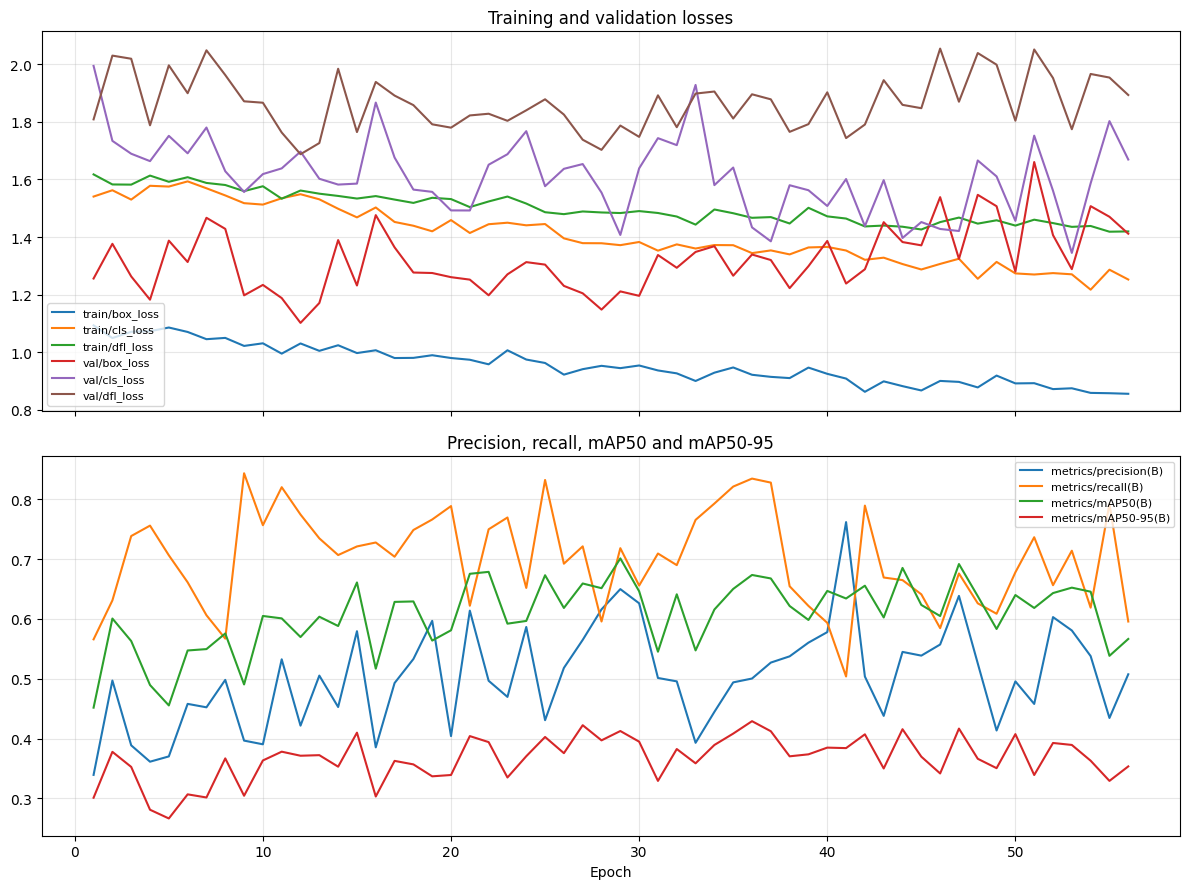

Saved: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\training_curves.png


In [ ]:
results_csv = TRAIN_RUN_DIR / "results.csv"
if not results_csv.is_file():
    raise FileNotFoundError(f"Ultralytics results.csv missing: {results_csv}")
training_results = pd.read_csv(results_csv)
training_results.columns = [c.strip() for c in training_results.columns]
plot_columns = [c for c in training_results.columns if any(term in c.lower() for term in ("loss", "precision", "recall", "map50"))]
if not plot_columns:
    raise ValueError("No loss/precision/recall/mAP columns found in results.csv")
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
loss_cols = [c for c in plot_columns if "loss" in c.lower()]
metric_cols = [c for c in plot_columns if c not in loss_cols]
for col in loss_cols:
    axes[0].plot(training_results.index + 1, training_results[col], label=col)
for col in metric_cols:
    axes[1].plot(training_results.index + 1, training_results[col], label=col)
axes[0].set_title("Training and validation losses")
axes[1].set_title("Precision, recall, mAP50 and mAP50-95")
for ax in axes:
    ax.grid(True, alpha=.3); ax.legend(loc="best", fontsize=8)
axes[1].set_xlabel("Epoch")
fig.tight_layout()
TRAINING_PLOT = EXPERIMENT_DIR / "training_curves.png"
fig.savefig(TRAINING_PLOT, dpi=160)
plt.show()
print("Saved:", TRAINING_PLOT)

## 9. Original model evaluation

In [ ]:
# Both models use this exact original test split and identical evaluation parameters.
TEST_EVAL_CONFIG = {"data": str(ORIGINAL_DATA_YAML), "split": "test", "imgsz": IMAGE_SIZE, "batch": 1 if GPU_AVAILABLE else 1, "device": DEVICE, "plots": True, "save_json": True, "conf": 0.001}
EVALUATION_DIR = EXPERIMENT_DIR / "evaluation"
EVALUATION_DIR.mkdir(parents=True, exist_ok=False)
def evaluate_checkpoint(checkpoint, name):
    model = YOLO(str(checkpoint))
    metrics = model.val(**TEST_EVAL_CONFIG, project=str(EVALUATION_DIR), name=name, exist_ok=False)
    return model, metrics

def metrics_record(metrics):
    box = metrics.box
    ids = [int(x) for x in getattr(box, "ap_class_index", [])]
    ap = np.asarray(getattr(box, "ap", [])); ap50 = np.asarray(getattr(box, "ap50", []))
    per_class = {}
    for i, cid in enumerate(ids):
        if ap.ndim == 2 and i < ap.shape[0]:
            ap95 = float(np.mean(ap[i]))
        else:
            ap95 = float(ap[i]) if ap.ndim == 1 and i < len(ap) else float("nan")
        per_class[CLASS_NAMES.get(cid, str(cid))] = {"precision": float(box.p[i]), "recall": float(box.r[i]), "mAP50": float(ap50[i]), "mAP50_95": ap95}
    return {"precision": float(box.mp), "recall": float(box.mr), "mAP50": float(box.map50), "mAP50_95": float(box.map), "per_class": per_class, "save_dir": str(getattr(metrics, "save_dir", ""))}

original_model, original_metrics = evaluate_checkpoint(BASE_CHECKPOINT, "original_best_test")
ORIGINAL_REPORT = metrics_record(original_metrics)
print("Original model test metrics:")
display(pd.DataFrame(ORIGINAL_REPORT["per_class"]).T)
print({k: ORIGINAL_REPORT[k] for k in ("precision", "recall", "mAP50", "mAP50_95")})
print("Confusion matrix and PR artifacts:", ORIGINAL_REPORT["save_dir"])

Ultralytics 8.4.194  Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 145.7±28.9 MB/s, size: 81.7 KB)
val: Scanning C:\Users\simra\potato_harvest\potato_yolo_dataset\labels\test.cache... 59 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 59/59 20.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 2.6it/s 22.6s<0.0s7
                   all         59         85      0.259      0.716      0.376      0.237
            Vegetative         16         20      0.307        0.3      0.311      0.198
         Tuber Bulking         31         37      0.285      0.919      0.499      0.341
              Maturity         22         28      0.185      0.929      0.317      0.171
Speed: 1.6ms preprocess, 19.6ms inference, 0.0ms loss, 1.8ms postprocess per imag

,precision,recall,mAP50,mAP50_95
Vegetative,0.306791,0.300000,0.311105,0.198339
Tuber Bulking,0.284571,0.918919,0.498516,0.340509
Maturity,0.185458,0.928571,0.317201,0.170751


{'precision': 0.2589398714844556, 'recall': 0.7158301158301158, 'mAP50': 0.37560755159602977, 'mAP50_95': 0.23653287910699916}
Confusion matrix and PR artifacts: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\evaluation\original_best_test


## 10. Improved model evaluation

In [ ]:
improved_model, improved_metrics = evaluate_checkpoint(IMPROVED_CHECKPOINT, "improved_best_test")
IMPROVED_REPORT = metrics_record(improved_metrics)
print("Improved model test metrics:")
display(pd.DataFrame(IMPROVED_REPORT["per_class"]).T)
print({k: IMPROVED_REPORT[k] for k in ("precision", "recall", "mAP50", "mAP50_95")})
print("Confusion matrix and PR artifacts:", IMPROVED_REPORT["save_dir"])

# Save side-by-side predictions for every original test image; prediction artifacts stay inside this experiment.
TEST_IMAGE_PATHS = [str(p) for p in SPLIT_IMAGES["test"]]
original_model.predict(source=TEST_IMAGE_PATHS, imgsz=IMAGE_SIZE, conf=0.25, batch=1, device=DEVICE, save=True, project=str(EXPERIMENT_DIR / "predictions"), name="original_test", exist_ok=False, verbose=False)
improved_model.predict(source=TEST_IMAGE_PATHS, imgsz=IMAGE_SIZE, conf=0.25, batch=1, device=DEVICE, save=True, project=str(EXPERIMENT_DIR / "predictions"), name="improved_test", exist_ok=False, verbose=False)
print("Prediction visualizations saved under:", EXPERIMENT_DIR / "predictions")

Ultralytics 8.4.194  Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 432.9±103.9 MB/s, size: 63.7 KB)
val: Scanning C:\Users\simra\potato_harvest\potato_yolo_dataset\labels\test.cache... 59 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 59/59 27.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 10.4it/s 5.7s0.0s
                   all         59         85      0.278      0.663      0.388      0.238
            Vegetative         16         20      0.326      0.267      0.332      0.193
         Tuber Bulking         31         37      0.313      0.865      0.434      0.297
              Maturity         22         28      0.196      0.857        0.4      0.225
Speed: 1.5ms preprocess, 15.2ms inference, 0.0ms loss, 1.7ms postprocess per image

,precision,recall,mAP50,mAP50_95
Vegetative,0.326482,0.267287,0.332030,0.192717
Tuber Bulking,0.312573,0.864865,0.433550,0.297052
Maturity,0.195979,0.857143,0.399589,0.225446


{'precision': 0.2783447943862239, 'recall': 0.6630983841679458, 'mAP50': 0.3883896744509308, 'mAP50_95': 0.23840519215164072}
Confusion matrix and PR artifacts: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\evaluation\improved_best_test
Results saved to C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\predictions\original_test
Results saved to C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\predictions\improved_test
Prediction visualizations saved under: C:\Users\simra\potato_harvest\runs\potato_yolov8n_finetune\20261112_095630\predictions


## 11. Model comparison

In [ ]:
comparison = pd.DataFrame({"Original YOLOv8n": {k: ORIGINAL_REPORT[k] for k in ("precision", "recall", "mAP50", "mAP50_95")}, "Fine-tuned YOLOv8n": {k: IMPROVED_REPORT[k] for k in ("precision", "recall", "mAP50", "mAP50_95")}})
comparison["difference"] = comparison["Fine-tuned YOLOv8n"] - comparison["Original YOLOv8n"]
class_comparison = {}
for class_name in CLASS_NAMES.values():
    class_comparison[class_name] = {}
    for metric_name in ("precision", "recall", "mAP50", "mAP50_95"):
        class_comparison[class_name][metric_name] = {
            "original": ORIGINAL_REPORT["per_class"].get(class_name, {}).get(metric_name, float("nan")),
            "improved": IMPROVED_REPORT["per_class"].get(class_name, {}).get(metric_name, float("nan")),
        }
        class_comparison[class_name][metric_name]["difference"] = class_comparison[class_name][metric_name]["improved"] - class_comparison[class_name][metric_name]["original"]
display(comparison)
display(pd.concat({k: pd.DataFrame(v).T for k, v in class_comparison.items()}, names=["class", "metric"]))
comparison_report = {"test_split": str((VERIFIED_DATASET / "images" / "test").resolve()), "test_image_count": len(SPLIT_IMAGES["test"]), "evaluation_config": TEST_EVAL_CONFIG, "original": ORIGINAL_REPORT, "improved": IMPROVED_REPORT, "overall_comparison": comparison.to_dict(), "class_comparison": class_comparison, "plot_independent_validation": False, "source_plot_group_overlap": plot_overlap}
(EXPERIMENT_DIR / "comparison_report.json").write_text(json.dumps(comparison_report, indent=2, allow_nan=True), encoding="utf-8")

,Original YOLOv8n,Fine-tuned YOLOv8n,difference
precision,0.258940,0.278345,0.019405
recall,0.715830,0.663098,-0.052732
mAP50,0.375608,0.388390,0.012782
mAP50_95,0.236533,0.238405,0.001872


original  improved  difference
class         metric                                   
Vegetative    precision  0.306791  0.326482    0.019692
              recall     0.300000  0.267287   -0.032713
              mAP50      0.311105  0.332030    0.020925
              mAP50_95   0.198339  0.192717   -0.005623
Tuber Bulking precision  0.284571  0.312573    0.028003
              recall     0.918919  0.864865   -0.054054
              mAP50      0.498516  0.433550   -0.064966
              mAP50_95   0.340509  0.297052   -0.043456
Maturity      precision  0.185458  0.195979    0.010520
              recall     0.928571  0.857143   -0.071429
              mAP50      0.317201  0.399589    0.082388
              mAP50_95   0.170751  0.225446    0.054696

4805

## 12. Final conclusion

In [ ]:
TEST_HASHES_AFTER = {str(p.relative_to(VERIFIED_DATASET)): sha256(p) for p in sorted(TEST_FILES)}
assert TEST_HASHES_BEFORE == TEST_HASHES_AFTER, "Original test images/labels changed during this experiment."
assert IMPROVED_CHECKPOINT.resolve() != BASE_CHECKPOINT.resolve()
assert IMPROVED_CHECKPOINT.is_file()
metric_name = "mAP50_95"
delta = IMPROVED_REPORT[metric_name] - ORIGINAL_REPORT[metric_name]
if delta > 1e-12:
    conclusion = f"Improved checkpoint has higher test {metric_name} by {delta:.4f}; this is an observed result on the existing test split, not evidence of plot-independent generalization."
elif delta < -1e-12:
    conclusion = f"Fine-tuned checkpoint has lower test {metric_name} by {abs(delta):.4f}; no accuracy improvement is demonstrated."
else:
    conclusion = f"Test {metric_name} is unchanged; no accuracy improvement is demonstrated."
final_summary = {
    "conclusion": conclusion,
    "checkpoint": str(IMPROVED_CHECKPOINT),
    "experiment_dir": str(EXPERIMENT_DIR),
    "prepared_yaml": str(PREPARED_YAML),
    "manifest": str(PREPARED_DATASET / "dataset_manifest.json"),
    "config": str(EXPERIMENT_DIR / "training_config.json"),
    "training_results": str(results_csv),
    "training_plot": str(TRAINING_PLOT),
    "comparison": str(EXPERIMENT_DIR / "comparison_report.json"),
    "unreviewed_pseudo_images_excluded": unreviewed_count,
    "approved_corrected_pseudo_images_used": len(PSEUDO_CANDIDATES),
    "test_files_unchanged": True,
    "validation_independent_by_source_plot": False,
}
(EXPERIMENT_DIR / "final_summary.json").write_text(json.dumps(final_summary, indent=2), encoding="utf-8")
print(conclusion)
print(json.dumps(final_summary, indent=2))

Fine-tuned checkpoint has lower test mAP50_95 by 0.0476; no accuracy improvement is demonstrated.
{
  "conclusion": "Fine-tuned checkpoint has lower test mAP50_95 by 0.0476; no accuracy improvement is demonstrated.",
  "checkpoint": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219\\training\\train_batch2\\weights\\best.pt",
  "experiment_dir": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219",
  "prepared_yaml": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219\\dataset\\data.yaml",
  "manifest": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219\\dataset\\dataset_manifest.json",
  "config": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219\\training_config.json",
  "training_results": "C:\\Users\\simra\\potato_harvest\\runs\\potato_yolov8n_finetune\\20261102_012219\\training\\train_batch2\\results.csv",
  "training_plot": "C:\

In [ ]:

from pathlib import Path
from collections import Counter

# Correct folder path based on your VS Code Explorer
LABEL_DIR = Path("../preannotations/approved_labels")

class_names = {
    0: "Vegetative",
    1: "Tuber Bulking",
    2: "Maturity"
}

image_counts = Counter()
box_counts = Counter()

# Check folder
print("Label folder:", LABEL_DIR.resolve())

if not LABEL_DIR.exists():
    raise FileNotFoundError("Approved labels folder not found. Check the path.")

# Get all label files, including nested folders
label_files = list(LABEL_DIR.rglob("*.txt"))

for label_file in label_files:
    classes_in_image = set()

    with open(label_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()

            if not parts:
                continue

            class_id = int(parts[0])

            if class_id in class_names:
                classes_in_image.add(class_id)
                box_counts[class_id] += 1

    # Count each class only once per image
    for class_id in classes_in_image:
        image_counts[class_id] += 1

print("\n========== IMAGE COUNT PER CLASS ==========")

for cid, name in class_names.items():
    print(f"Class {cid} ({name}): {image_counts[cid]} images")

print("\n========== BOUNDING BOX COUNT PER CLASS ==========")

for cid, name in class_names.items():
    print(f"Class {cid} ({name}): {box_counts[cid]} boxes")

print("\nTotal label files:", len(label_files))


Label folder: C:\Users\simra\potato_harvest\preannotations\approved_labels

========== IMAGE COUNT PER CLASS ==========
Class 0 (Vegetative): 1046 images
Class 1 (Tuber Bulking): 2357 images
Class 2 (Maturity): 1118 images

========== BOUNDING BOX COUNT PER CLASS ==========
Class 0 (Vegetative): 1419 boxes
Class 1 (Tuber Bulking): 3625 boxes
Class 2 (Maturity): 2143 boxes

Total label files: 3002


In [ ]:
from pathlib import Path

empty_labels = []
non_empty_labels = []

for p in LABEL_DIR.rglob("*.txt"):
    if p.stat().st_size == 0:
        empty_labels.append(p)
    else:
        non_empty_labels.append(p)

print("Total label files:", len(empty_labels) + len(non_empty_labels))
print("Empty labels:", len(empty_labels))
print("Non-empty labels:", len(non_empty_labels))

Total label files: 3002
Empty labels: 3
Non-empty labels: 2999
